In [32]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.clean import run_cleaning
from src.analysis import load_clean, compute_changes, label_decoupling, top_decouplers, run_ttest

# Is Economic Growth Decoupling from Carbon Emissions?

In [33]:
emissions_df = load_clean()
emissions_df.head()

,iso_code,country,gdp_pct_change,co2_pct_change,co2_per_gdp_pct_change,decoupled
0,AFG,Afghanistan,109.875301,368.585369,123.268468,False
1,AGO,Angola,204.701485,40.054815,-54.035401,False
2,ALB,Albania,75.904629,-0.471615,-43.419121,True
3,ARE,United Arab Emirates,197.127316,91.317309,-35.610999,False
4,ARG,Argentina,42.236714,16.037343,-18.419556,False


In [34]:
top_year = 2022

top_emitters = (
    emissions_df.loc[emissions_df["year"] == top_year, ["country", "co2"]]
    .nlargest(10, "co2")
    .reset_index(drop=True)
)

display(top_emitters)

KeyError: 'year'

,year,co2,countries
28,2018,35536.037778,164
29,2019,35729.542172,164
30,2020,34163.669251,164
31,2021,35917.726023,164
32,2022,36373.761568,164


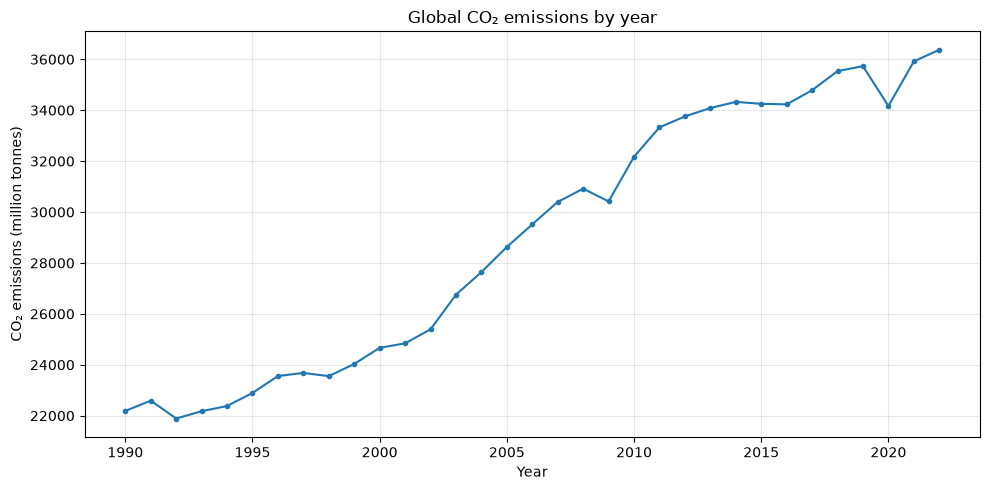

In [ ]:
global_trend = (
    emissions_df.groupby("year", as_index=False)
    .agg(
        co2=("co2", "sum"),
        countries=("iso_code", "nunique"),
    )
    .sort_values("year")
)

display(global_trend.tail())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(global_trend["year"], global_trend["co2"], marker=".")
ax.set(
    title="Global CO₂ emissions by year",
    xlabel="Year",
    ylabel="CO₂ emissions (million tonnes)",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from config import BASE_YEAR, END_YEAR, FIGURES_DIR

changes = label_decoupling(compute_changes(emissions_df))
top_decoupling_results = top_decouplers(changes, n=10)
ttest_results = run_ttest(changes)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Comparison period: {BASE_YEAR}-{END_YEAR}")
print(f"Countries with complete endpoint data: {len(changes)}")
print(f"Countries with GDP growth and falling CO₂: {changes['decoupled'].sum()}")
print("\nTop decouplers by CO₂ percentage reduction:")
print(top_decoupling_results.to_string(index=False))
print("\nWelch's t-test on CO₂-intensity percentage change:")
for key, value in ttest_results.items():
    print(f"{key}: {value:.4g}" if isinstance(value, float) else f"{key}: {value}")

Comparison period: 2005-2022
Countries with complete endpoint data: 164
Countries with GDP growth and falling CO₂: 44

Top decouplers by CO₂ percentage reduction:
       country  gdp_pct_change  co2_pct_change
United Kingdom       20.978625      -45.576230
       Denmark       30.712388      -42.658350
      Portugal       16.332215      -41.658532
    Luxembourg       45.252102      -39.807561
         Spain       20.484284      -37.143890
       Finland       17.184304      -36.331076
       Jamaica        4.403059      -33.063849
         Malta      106.962049      -33.043747
         Italy        5.261364      -32.824202
       Romania      106.823362      -32.495124

Welch's t-test on CO₂-intensity percentage change:
n_decoupled: 44
n_other: 120
mean_decoupled: -45.61
mean_other: 9.797
t_stat: -8.107
p_value: 3.07e-13


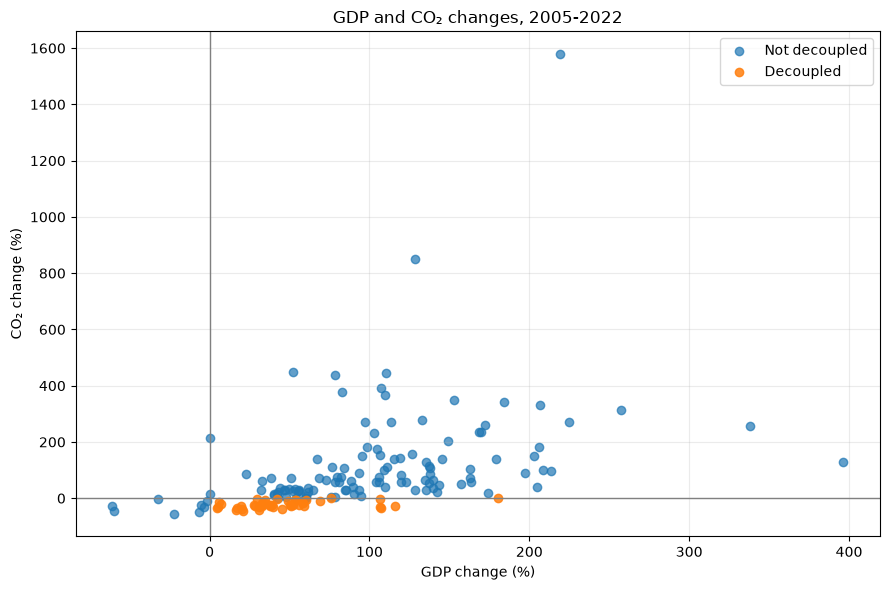

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
other = changes.loc[~changes["decoupled"]]
decoupled = changes.loc[changes["decoupled"]]
ax.scatter(other["gdp_pct_change"], other["co2_pct_change"], label="Not decoupled", alpha=0.7)
ax.scatter(decoupled["gdp_pct_change"], decoupled["co2_pct_change"], label="Decoupled", alpha=0.85)
ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)
ax.set(title=f"GDP and CO₂ changes, {BASE_YEAR}-{END_YEAR}", xlabel="GDP change (%)", ylabel="CO₂ change (%)")
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "decoupling_scatter.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

Line-chart case studies (first group decoupled, second group not decoupled):
['United Kingdom', 'Denmark', 'Portugal', 'Laos', 'Cambodia', 'Mozambique']


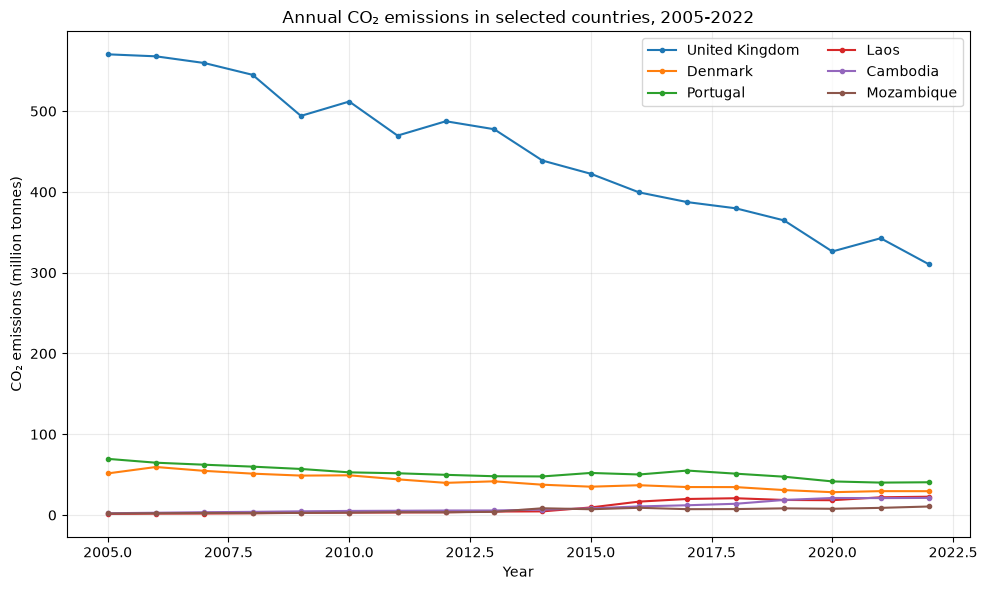

In [ ]:
decoupler_cases = decoupled.nsmallest(3, "co2_pct_change")["country"].tolist()
other_cases = other.nlargest(3, "co2_pct_change")["country"].tolist()
case_countries = decoupler_cases + other_cases
print("Line-chart case studies (first group decoupled, second group not decoupled):")
print(case_countries)
case_data = emissions_df.loc[
    emissions_df["country"].isin(case_countries)
    & emissions_df["year"].between(BASE_YEAR, END_YEAR)
].sort_values("year")
fig, ax = plt.subplots(figsize=(10, 6))
for country in case_countries:
    country_data = case_data.loc[case_data["country"] == country]
    ax.plot(country_data["year"], country_data["co2"], marker=".", label=country)
ax.set(title=f"Annual CO₂ emissions in selected countries, {BASE_YEAR}-{END_YEAR}", xlabel="Year", ylabel="CO₂ emissions (million tonnes)")
ax.legend(ncol=2)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "decoupling_case_studies.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

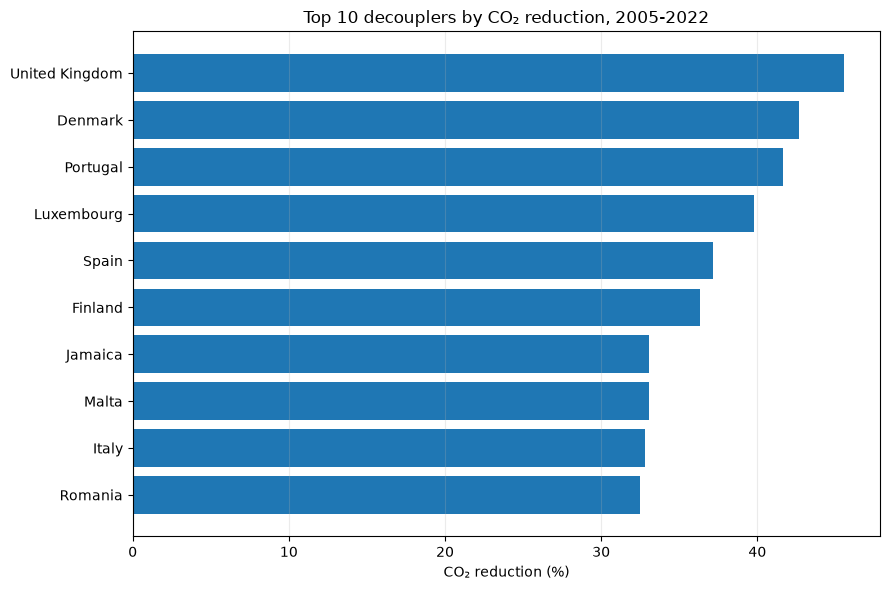

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
if top_decoupling_results.empty:
    ax.text(0.5, 0.5, "No countries met the decoupling definition", ha="center", va="center")
    ax.set_axis_off()
else:
    ax.barh(top_decoupling_results["country"], -top_decoupling_results["co2_pct_change"])
    ax.invert_yaxis()
    ax.set_xlabel("CO₂ reduction (%)")
    ax.grid(axis="x", alpha=0.25)
ax.set_title(f"Top 10 decouplers by CO₂ reduction, {BASE_YEAR}-{END_YEAR}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "top_decouplers.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# Preparing csv file for dashboard

In [35]:
from src.analysis import load_clean, compute_changes, label_decoupling
from config import CHANGES_PATH

df = load_clean()
changes = label_decoupling(compute_changes(df))
changes.to_csv(CHANGES_PATH, index=False)

ImportError: cannot import name 'CHANGES_PATH' from 'config' (c:\Users\Advait\Documents\all_code\datasci\co2_decoupling_analysis\notebooks\..\config.py)